In [27]:
import sqlite3
import pandas as pd
import numpy as np

con = sqlite3.connect("file:../data/wjazzd.db?mode=ro&immutable=1", uri=True)

notes = pd.read_sql("SELECT melid, onset, pitch, bar, beat, tatum, num FROM melody", con)
beats = pd.read_sql("SELECT melid, onset, chord FROM beats", con)
solos = pd.read_sql("SELECT melid, performer, title, instrument FROM solo_info", con)

In [28]:
beats["chord"] = beats["chord"].replace("", np.nan)   # case vide -> valeur manquante
beats = beats.sort_values(["melid", "onset"])
beats["chord"] = beats.groupby("melid")["chord"].ffill()
beats.head(12)

,melid,onset,chord
0,1,9.171882,NaN
1,1,9.488254,NaN
2,1,9.779955,NaN
3,1,10.052608,NaN
4,1,10.339796,Bb6
5,1,10.631542,Bb6
6,1,10.918163,Bb6
7,1,11.217007,Bb6
8,1,11.514127,Bb6
9,1,11.824150,Bb6


In [29]:
notes = pd.merge_asof(
    notes.sort_values("onset"), beats.sort_values("onset"),
    on="onset", by="melid", direction="backward")
notes = notes.sort_values(["melid", "onset"]).reset_index(drop=True)
notes[["melid", "onset", "pitch", "chord"]].head(8)

,melid,onset,pitch,chord
0,1,10.343492,65.0,Bb6
1,1,10.637642,63.0,Bb6
2,1,10.843719,58.0,Bb6
3,1,10.948209,61.0,Bb6
4,1,11.232653,63.0,Bb6
5,1,11.551927,58.0,Bb6
6,1,11.859592,58.0,Bb6
7,1,14.535692,50.0,G-7


In [30]:
NOTE_TO_PC = {"C": 0, "D": 2, "E": 4, "F": 5, "G": 7, "A": 9, "B": 11}
QUALITIES = [   # du plus spécifique au plus général : l'ordre compte !
    ("m7b5", "half-diminished", {0, 3, 6, 10}),
    ("-j7", "minor-major 7", {0, 3, 7, 11}),
    ("-7", "minor 7", {0, 3, 7, 10}),
    ("-6", "minor 6", {0, 3, 7, 9}),
    ("-", "minor", {0, 3, 7}),
    ("o7", "diminished 7", {0, 3, 6, 9}),
    ("o", "diminished", {0, 3, 6}),
    ("+7", "augmented 7", {0, 4, 8, 10}),
    ("+", "augmented", {0, 4, 8}),
    ("j7", "major 7", {0, 4, 7, 11}),
    ("sus7", "sus 7", {0, 5, 7, 10}),
    ("sus", "sus", {0, 5, 7}),
    ("6", "major 6", {0, 4, 7, 9}),
    ("7", "dominant 7", {0, 4, 7, 10}),
]

def parse_chord(label):
    """'Bb7' -> (10, 'dominant 7', {0, 4, 7, 10}) ; 'NC' ou vide -> None"""
    if not isinstance(label, str) or label == "NC":
        return None
    label = label.split("/")[0]                    # 'C-/Bb' -> 'C-' (on ignore la basse)
    root = NOTE_TO_PC.get(label[0])
    if root is None:
        return None
    rest = label[1:]
    if rest[:1] in ("b", "#"):                     # altération : Bb, F#
        root = (root + (-1 if rest[0] == "b" else 1)) % 12
        rest = rest[1:]
    for prefix, family, tones in QUALITIES:
        if rest.startswith(prefix):
            return root, family, tones
    if rest == "" or rest[0].isdigit():            # 'C', 'C69' -> accord majeur
        return root, "major", {0, 4, 7}
    return None

print(parse_chord("Bb7"), parse_chord("C-7"), parse_chord("Am7b5"), parse_chord("NC"))

(10, 'dominant 7', {0, 10, 4, 7}) (0, 'minor 7', {0, 10, 3, 7}) (9, 'half-diminished', {0, 10, 3, 6}) None


In [31]:
parsed = notes["chord"].map(parse_chord)
notes = notes[parsed.notna()].copy()
parsed = parsed[parsed.notna()]

notes["root"] = [p[0] for p in parsed]
notes["family"] = [p[1] for p in parsed]
notes["pitch"] = notes["pitch"].round().astype(int)
notes["interval"] = (notes["pitch"] - notes["root"]) % 12
notes["is_chord_tone"] = [i in p[2] for i, p in zip(notes["interval"], parsed)]
print(len(notes))

192980


In [32]:
on_beat = notes["tatum"] == 1                      # la note tombe pile sur un temps
strong = on_beat & np.where(notes["num"] == 4,
                            notes["beat"].isin([1, 3]),   # en 4/4 : temps 1 et 3
                            notes["beat"] == 1)           # sinon : temps 1
notes["position"] = np.select([strong, on_beat], ["strong beat", "weak beat"], "off-beat")
notes["position"].value_counts()

position
off-beat       131514
strong beat     31854
weak beat       29612
Name: count, dtype: int64

In [33]:
# Si on choisissait une note au hasard parmi 12, la probabilité de tomber dans l'accord
# = (nombre de notes de l'accord) / 12, soit 3/12 pour une triade et 4/12 pour un accord de 4 sons.
size = notes["family"].map(lambda f: 3 if f in {"major", "minor", "diminished", "augmented", "sus"} else 4)
chance = (size / 12).mean()
print(f"Chord tones: {notes['is_chord_tone'].mean():.1%}  vs chance: {chance:.1%}")
notes.groupby("position")["is_chord_tone"].mean()

Chord tones: 49.1%  vs chance: 32.5%


position
off-beat       0.480785
strong beat    0.512086
weak beat      0.514420
Name: is_chord_tone, dtype: float64

In [34]:
g = notes.groupby("melid")
next_pitch = g["pitch"].shift(-1)
next_ct = g["is_chord_tone"].shift(-1).fillna(False).astype(bool)
notes["is_approach"] = ~notes["is_chord_tone"] & next_ct & ((next_pitch - notes["pitch"]).abs() == 1)
print(f"{notes.loc[~notes['is_chord_tone'], 'is_approach'].mean():.1%} of non-chord tones resolve by a half step")

19.3% of non-chord tones resolve by a half step


In [35]:
notes = notes.merge(solos, on="melid", how="left")
(notes[notes["position"] == "strong beat"]
 .groupby("instrument")
 .agg(solos=("melid", "nunique"), chord_tone_share=("is_chord_tone", "mean"))
 .sort_values("solos", ascending=False))

,solos,chord_tone_share
instrument,,
ts,156,0.506162
tp,101,0.496683
as,74,0.523295
tb,26,0.551052
ss,22,0.466258
cl,15,0.593558
cor,15,0.554745
vib,12,0.614706
bs,11,0.529730


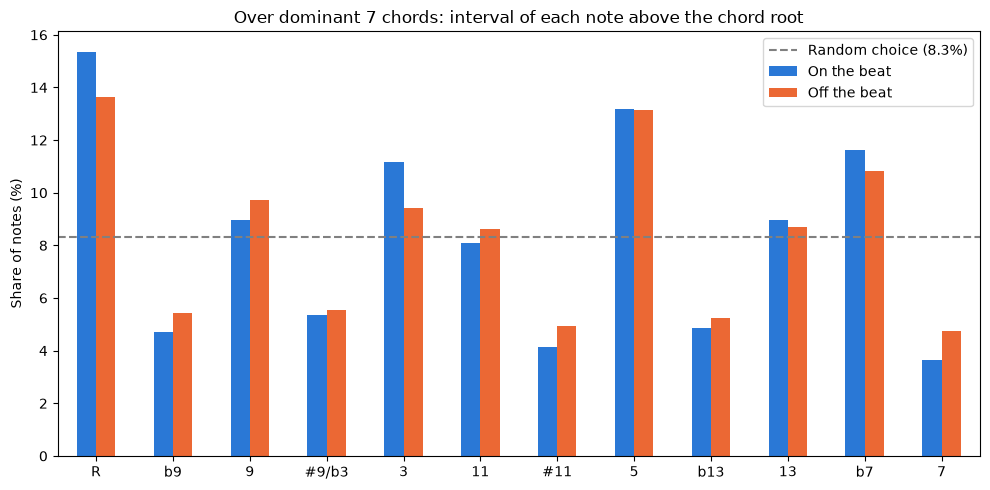

In [38]:
import matplotlib.pyplot as plt

names = ["R", "b9", "9", "#9/b3", "3", "11", "#11", "5", "b13", "13", "b7", "7"]
dom = notes[notes["family"] == "dominant 7"].copy()
dom["on_beat"] = np.where(dom["position"] == "off-beat", "Off the beat", "On the beat")
profile = pd.crosstab(dom["interval"], dom["on_beat"], normalize="columns") * 100
profile.index = names

ax = profile[["On the beat", "Off the beat"]].plot.bar(figsize=(10, 5), color=["#2a78d6", "#eb6834"], rot=0)
ax.axhline(100 / 12, ls="--", color="gray", label="Random choice (8.3%)")
ax.set_ylabel("Share of notes (%)")
ax.set_title("Over dominant 7 chords: interval of each note above the chord root")
ax.legend()
plt.tight_layout()
plt.savefig("../figures/dominant7_interval_profile.png", dpi=200)